# 🏭 Production Line Digital Twin — Part 3: KPI Dashboard & OEE
Using the data from Part 2, we calculate the KPIs a factory manager watches every day:
**OEE (Availability × Performance × Quality), throughput, yield, lead time, MTBF, MTTR**.

### Imports

In [13]:
import os
import pandas as pd
import matplotlib.pyplot as plt

### Settings and data
These must match Part 2 ($10 \times 480 = 4800$ min). Load the three CSVs created there.

In [14]:
# ⚠️ These must match the settings used in Step 2
SHIFTS = 10
SHIFT_LENGTH = 480                    # minutes per shift
SIM_TIME = SHIFTS * SHIFT_LENGTH      # 4800 minutes
STATIONS = {                          # ideal (average) processing time per station
    "Cutting":    4,
    "Welding":    6,
    "Painting":   5,
    "Inspection": 3,
}

# Load the 3 datasets created in Step 2
production = pd.read_csv("../data/production_log.csv")
sensors    = pd.read_csv("../data/sensor_log.csv")
failures   = pd.read_csv("../data/failure_log.csv")

print(f"Production rows: {len(production)}")
print(f"Sensor rows:     {len(sensors)}")
print(f"Failures:        {len(failures)}")

Production rows: 3207
Sensor rows:     19200
Failures:        53


### One row per finished part
- **Finished:** the part's `end_time` at Inspection.
- **Entered:** the part's `arrival_time` at Cutting.
- Merge the two on `part_id`.

$$\text{lead time} = \text{end at Inspection} - \text{arrival at Cutting}$$

A part is **good** if no station made a defect on it. The shift it finished in is
$$\text{shift} = \left\lfloor \frac{\text{end time}}{480} \right\rfloor + 1$$

In [15]:
# A part is FINISHED when it has left the last station (Inspection)
finished = production[production["station"] == "Inspection"][["part_id", "end_time"]]

# When did each part ENTER the line? (its arrival at the first station, Cutting)
entered = production[production["station"] == "Cutting"][["part_id", "arrival_time"]]

# Join the two tables on part_id (like VLOOKUP in Excel)
parts = finished.merge(entered, on="part_id")

# Lead time = total time from entering the line to leaving it
parts["lead_time"] = parts["end_time"] - parts["arrival_time"]

# A part is GOOD only if NO station made a defect on it
defective_ids = production.loc[production["defect"], "part_id"].unique()
parts["good"] = ~parts["part_id"].isin(defective_ids)     # ~ means "NOT"

# Which shift was the part finished in? (0–479 min = shift 1, 480–959 = shift 2, ...)
parts["shift"] = (parts["end_time"] // SHIFT_LENGTH).astype(int) + 1

parts.head()

,part_id,end_time,arrival_time,lead_time,good,shift
0,1,23.156233,5.100301,18.055932,True,1
1,2,28.020058,7.369632,20.650426,True,1
2,3,35.407593,7.532765,27.874828,True,1
3,4,40.812201,9.427756,31.384445,False,1
4,5,47.634050,10.008454,37.625596,True,1


### Headline KPIs for the whole line
$$\text{Yield} = \frac{\text{good parts}}{\text{finished parts}} \times 100 \qquad \text{Throughput} = \frac{\text{finished parts}}{\text{shifts}}$$

$$\text{Avg lead time} = \text{mean}(\text{lead time}) \qquad \text{WIP} = \text{parts that passed Cutting} - \text{finished parts}$$

WIP (work in progress) is the number of parts still inside the line when the simulation stops.

In [16]:
total_finished = len(parts)
good_parts     = parts["good"].sum()
scrap_parts    = total_finished - good_parts
yield_pct      = good_parts / total_finished * 100
throughput     = total_finished / SHIFTS
avg_lead_time  = parts["lead_time"].mean()

# Work in progress (WIP): parts that passed Cutting but hadn't finished when the simulation ended
wip_at_end     = len(entered) - total_finished

print("📊 LINE KPIs")
print(f"  Finished parts:       {total_finished}")
print(f"  Good parts:           {good_parts}")
print(f"  Scrap parts:          {scrap_parts}")
print(f"  Yield:                {yield_pct:.1f}%")
print(f"  Throughput:           {throughput:.1f} parts per shift")
print(f"  Average lead time:    {avg_lead_time:.0f} minutes")
print(f"  Parts stuck in line:  {wip_at_end} (at the end of the simulation)")

📊 LINE KPIs
  Finished parts:       744
  Good parts:           631
  Scrap parts:          113
  Yield:                84.8%
  Throughput:           74.4 parts per shift
  Average lead time:    559 minutes
  Parts stuck in line:  228 (at the end of the simulation)


### OEE for each station
**OEE (Overall Equipment Effectiveness)** = Availability × Performance × Quality.

| Factor | Formula | Measures |
|---|---|---|
| Availability | $\dfrac{\text{planned time} - \text{downtime}}{\text{planned time}}$ | time lost to breakdowns |
| Performance | $\dfrac{\text{ideal cycle time} \times \text{total parts}}{\text{run time}}$ (capped at 1) | time lost to running slow or sitting idle |
| Quality | $\dfrac{\text{good parts}}{\text{total parts}}$ | parts lost to defects |

Downtime per failure is $\min(\text{failure time} + \text{repair time},\ 4800) - \text{failure time}$, so repairs past the end of the simulation aren't counted.

**Reliability:**
$$\text{MTBF} = \frac{\text{run time}}{\text{failures}} \qquad \text{MTTR} = \frac{\text{downtime}}{\text{failures}}$$
MTBF is the mean time between failures and MTTR is the mean time to repair. A station with 0 failures shows `inf`/`NaN` here.

In [17]:
oee = pd.DataFrame(index=list(STATIONS.keys()))       # one row per station
oee["ideal_cycle_min"] = pd.Series(STATIONS)

# --- Downtime ---
# A repair that started near the end could "finish" after the simulation ended.
# clip() cuts it off at SIM_TIME so we only count downtime inside our time window.
failures["repair_end"] = (failures["failure_time"] + failures["repair_time"]).clip(upper=SIM_TIME)
failures["downtime"]   = failures["repair_end"] - failures["failure_time"]

oee["failures"]     = failures.groupby("station").size()
oee["downtime_min"] = failures.groupby("station")["downtime"].sum()
oee = oee.fillna(0)                                    # stations with no failures get 0

# --- Time ---
oee["planned_min"]  = SIM_TIME
oee["run_time_min"] = oee["planned_min"] - oee["downtime_min"]

# --- Parts ---
oee["total_parts"] = production.groupby("station").size()
oee["good_parts"]  = production[~production["defect"]].groupby("station").size()

# --- The 3 OEE factors (as fractions between 0 and 1) ---
oee["availability"] = oee["run_time_min"] / oee["planned_min"]
# Performance: time the parts SHOULD have taken ÷ time the machine was available.
# clip(upper=1.0) caps it at 100%, since random variation can push it slightly above.
oee["performance"]  = (oee["ideal_cycle_min"] * oee["total_parts"] / oee["run_time_min"]).clip(upper=1.0)
oee["quality"]      = oee["good_parts"] / oee["total_parts"]
oee["OEE"]          = oee["availability"] * oee["performance"] * oee["quality"]

# --- Reliability KPIs ---
oee["MTBF_min"] = oee["run_time_min"] / oee["failures"]    # avg running time between breakdowns
oee["MTTR_min"] = oee["downtime_min"] / oee["failures"]    # avg repair duration

# Show the OEE factors as percentages
(oee[["availability", "performance", "quality", "OEE"]] * 100).round(1)

,availability,performance,quality,OEE
Cutting,90.4,89.6,96.4,78.1
Welding,93.8,99.4,94.4,88.0
Painting,92.2,84.1,95.6,74.2
Inspection,92.3,50.4,96.4,44.8


### Reliability table

In [18]:
oee[["failures", "downtime_min", "MTBF_min", "MTTR_min"]].round(1)

,failures,downtime_min,MTBF_min,MTTR_min
Cutting,16,462.9,271.1,28.9
Welding,11,298.3,409.2,27.1
Painting,13,372.9,340.5,28.7
Inspection,13,370.0,340.8,28.5


### OEE for the whole line
The line can't go faster than its slowest station: Welding at 6 min/part.

$$\text{max possible} = \frac{4800}{6} = 800 \text{ parts} \qquad \text{Line OEE} = \frac{\text{good parts}}{\text{max possible}}$$

85% is the usual "world class" benchmark.

In [19]:
# The line can never produce faster than its slowest station (the bottleneck).
bottleneck   = max(STATIONS, key=STATIONS.get)            # station with the largest ideal time
max_possible = SIM_TIME / STATIONS[bottleneck]            # the most parts possible in perfect conditions
line_oee     = good_parts / max_possible

print(f"Bottleneck station:           {bottleneck} ({STATIONS[bottleneck]} min/part)")
print(f"Max possible parts (perfect): {max_possible:.0f}")
print(f"Good parts actually produced: {good_parts}")
print(f"🏭 LINE OEE:                  {line_oee:.1%}   (world class = 85%)")

Bottleneck station:           Welding (6 min/part)
Max possible parts (perfect): 800
Good parts actually produced: 631
🏭 LINE OEE:                  78.9%   (world class = 85%)


### Time split per machine (from sensor data)
There is one sensor reading per minute, so the number of readings in a status equals the minutes spent in it.

$$\text{\% in status} = \frac{\text{readings in status}}{\text{all readings of that station}} \times 100$$

`unstack` turns statuses into columns, and `div(..., axis=0)` divides each row by its own total.

In [20]:
# Share of sensor readings (= minutes) each station spent in each status, in %
# normalize="index" divides every row by its own total
states = pd.crosstab(sensors["station"], sensors["status"], normalize="index") * 100

# Put stations in line order and the statuses in a fixed order
states = states.reindex(index=STATIONS.keys(), columns=["running", "idle", "broken"], fill_value=0)
states.round(1)

status,running,idle,broken
station,,,
Cutting,80.9,9.4,9.7
Welding,93.4,0.4,6.2
Painting,77.6,14.6,7.8
Inspection,46.6,45.7,7.7


### Dashboard
A 2×2 grid:
1. OEE factors per station, with the 85% line
2. good vs scrap parts per shift
3. how each machine spent its time
4. lead time of every part over time. An upward trend means the queue is growing.

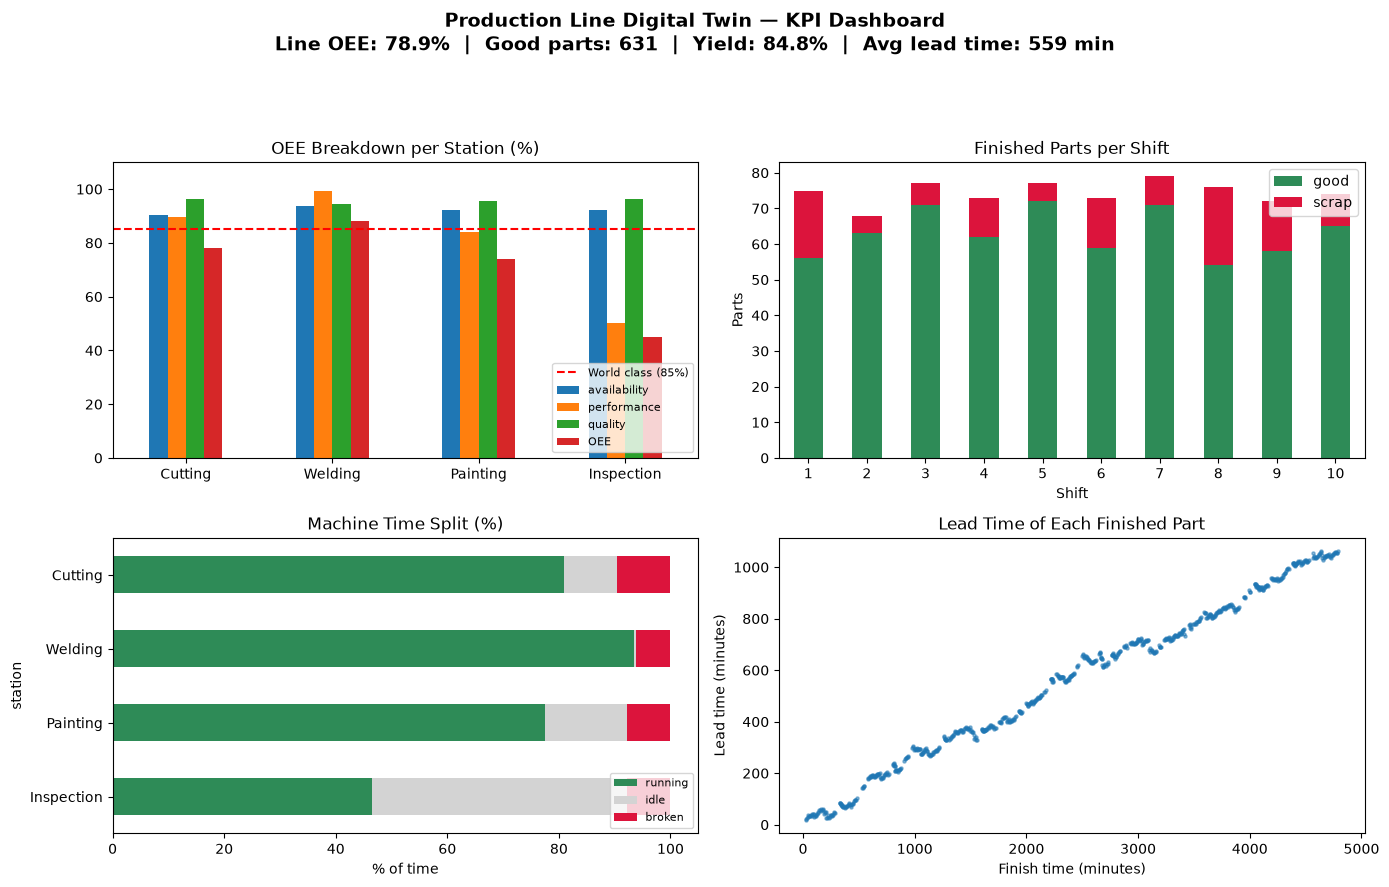

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))      # a 2×2 grid of charts
fig.suptitle(
    "Production Line Digital Twin — KPI Dashboard\n"
    f"Line OEE: {line_oee:.1%}  |  Good parts: {good_parts}  |  "
    f"Yield: {yield_pct:.1f}%  |  Avg lead time: {avg_lead_time:.0f} min",
    fontsize=14, fontweight="bold",
)

# --- Chart 1 (top-left): OEE factors per station ---
ax = axes[0, 0]
(oee[["availability", "performance", "quality", "OEE"]] * 100).plot(kind="bar", ax=ax, rot=0)
ax.axhline(85, color="red", linestyle="--", label="World class (85%)")
ax.set_title("OEE Breakdown per Station (%)")
ax.set_ylim(0, 110)
ax.legend(loc="lower right", fontsize=8)

# --- Chart 2 (top-right): good vs scrap parts per shift ---
ax = axes[0, 1]
per_shift = parts.groupby("shift")["good"].agg(good="sum", total="count")
per_shift["scrap"] = per_shift["total"] - per_shift["good"]
per_shift[["good", "scrap"]].plot(kind="bar", stacked=True, ax=ax, rot=0,
                                  color=["seagreen", "crimson"])
ax.set_title("Finished Parts per Shift")
ax.set_xlabel("Shift")
ax.set_ylabel("Parts")

# --- Chart 3 (bottom-left): how each machine spent its time ---
ax = axes[1, 0]
states.plot(kind="barh", stacked=True, ax=ax, color=["seagreen", "lightgray", "crimson"])
ax.set_title("Machine Time Split (%)")
ax.set_xlabel("% of time")
ax.invert_yaxis()                                    # Cutting at the top, like the real line order
ax.legend(loc="lower right", fontsize=8)

# --- Chart 4 (bottom-right): lead time of every finished part ---
ax = axes[1, 1]
ax.scatter(parts["end_time"], parts["lead_time"], s=5, alpha=0.5)
ax.set_title("Lead Time of Each Finished Part")
ax.set_xlabel("Finish time (minutes)")
ax.set_ylabel("Lead time (minutes)")

plt.tight_layout(rect=[0, 0, 1, 0.92])               # leave space at the top for the big title
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/03_kpi_dashboard.png", dpi=120)
plt.show()

### Automatic insights
`idxmin` and `idxmax` find the worst station for each KPI.

In [22]:
worst_oee      = oee["OEE"].idxmin()
most_failures  = oee["failures"].idxmax()
lowest_quality = oee["quality"].idxmin()
most_idle      = states["idle"].idxmax()

print("💡 INSIGHTS")
print(f"  • Lowest OEE:        {worst_oee} ({oee.loc[worst_oee, 'OEE']:.1%})")
print(f"  • Most breakdowns:   {most_failures} ({int(oee.loc[most_failures, 'failures'])} failures, "
      f"MTTR {oee.loc[most_failures, 'MTTR_min']:.0f} min)")
print(f"  • Worst quality:     {lowest_quality} ({oee.loc[lowest_quality, 'quality']:.1%} good)")
print(f"  • Most idle machine: {most_idle} ({states.loc[most_idle, 'idle']:.0f}% of time waiting for parts)")
print(f"  • Bottleneck:        {bottleneck}. Improving it raises the output of the WHOLE line.")

💡 INSIGHTS
  • Lowest OEE:        Inspection (44.8%)
  • Most breakdowns:   Cutting (16 failures, MTTR 29 min)
  • Worst quality:     Welding (94.4% good)
  • Most idle machine: Inspection (46% of time waiting for parts)
  • Bottleneck:        Welding. Improving it raises the output of the WHOLE line.


### Save per-station KPIs

In [23]:
oee.round(3).to_csv("../data/kpi_per_station.csv")
print("Saved data/kpi_per_station.csv 💾")

Saved data/kpi_per_station.csv 💾


## 📝 Conclusions
- The bottleneck is **Welding** (6 min/part). It runs 93.4% of the time and is idle only 0.4% of the time. Its OEE (88.0%) is the highest, as you'd expect for the busiest machine.
- The lead time chart shows that lead time **keeps growing**, from about 55 min in shift 1 to over 1,000 min in shift 10. The line is not stable: parts arrive faster than Welding can process them, so **228 parts** were still stuck in the line at the end.
- The machine with the lowest OEE is **Inspection (44.8%)** because of its low performance (50.4%). It is fast (3 min/part) but is starved of parts by Welding and sits idle 46% of the time. This is a symptom of the bottleneck, not a problem with Inspection.
- Line OEE is **78.9%**, below the 85% world-class benchmark. Yield is 84.8%, which means 113 scrap parts.
- To improve the line, I would:
  1. raise Welding's capacity (a second or faster welder),
  2. reduce breakdowns with preventive maintenance,
  3. reduce defects by keeping machines in better health.

  Part 4 tests these options.